Fine-tune hyperparameters with automated tools like Optuna, leveraging pruning strategies and advanced search algorithms to optimize model performance and minimize overfitting in high-dimensional spaces.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from scipy.stats import loguniform, randint
from sklearn.experimental import enable_halving_search_cv 
from sklearn.model_selection import StratifiedKFold, HalvingRandomSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, f1_score

In [5]:
np.random.seed(42)
n_samples = 1200
n_features = 15

In [6]:
X_mat = np.random.normal(0, 1, size=(n_samples, n_features))
feature_cols = [f"clinical_biomarker_{i+1}" for i in range(n_features)]

In [7]:
logits = (
    0.75 * X_mat[:, 0]
    - 0.90 * X_mat[:, 1]
    + 0.50 * (X_mat[:, 2] ** 2)
    + 1.25 * X_mat[:, 3] * X_mat[:, 4]
    - 0.80 * np.sin(X_mat[:, 5])
    - 1.10
)

In [8]:
probs = 1 / (1 + np.exp(-logits))
target = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [9]:
df_opt = pd.DataFrame(X_mat, columns=feature_cols)
df_opt['high_risk_flag'] = target

In [10]:
X = df_opt.drop(columns=['high_risk_flag'])
y = df_opt['high_risk_flag']

In [11]:
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), feature_cols)]
)

In [12]:
model = HistGradientBoostingClassifier(
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42
)

In [13]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', model)
])

In [14]:
param_distributions = {
    'classifier__learning_rate': loguniform(0.005, 0.2),
    'classifier__max_iter': randint(50, 200),
    'classifier__max_leaf_nodes': randint(15, 63),
    'classifier__min_samples_leaf': randint(10, 50),
    'classifier__l2_regularization': loguniform(1e-3, 10.0)
}

In [15]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
halving_search = HalvingRandomSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    scoring='f1',
    cv=cv_strategy,
    factor=3,                  
    resource='n_samples',
    max_resources='auto',
    random_state=42,
    n_jobs=1                  
)

In [17]:
t0 = time.perf_counter()
halving_search.fit(X, y)
t1 = time.perf_counter()

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [18]:
print("--- Automated Hyperparameter Fine-Tuning Summary ---")
print(f"Total Search Time        : {(t1 - t0):.2f} seconds")
print(f"Best Validation F1-Score : {halving_search.best_score_:.4f}")

--- Automated Hyperparameter Fine-Tuning Summary ---
Total Search Time        : 44.92 seconds
Best Validation F1-Score : 0.5713


In [19]:
print("\nBest Hyperparameters Identified:")
for param_name, param_val in halving_search.best_params_.items():
    clean_name = param_name.replace('classifier__', '')
    if isinstance(param_val, float):
        print(f"  • {clean_name}: {param_val:.5f}")
    else:
        print(f"  • {clean_name}: {param_val}")


Best Hyperparameters Identified:
  • l2_regularization: 0.00685
  • learning_rate: 0.05945
  • max_iter: 176
  • max_leaf_nodes: 41
  • min_samples_leaf: 11


In [20]:
cv_results = pd.DataFrame(halving_search.cv_results_)

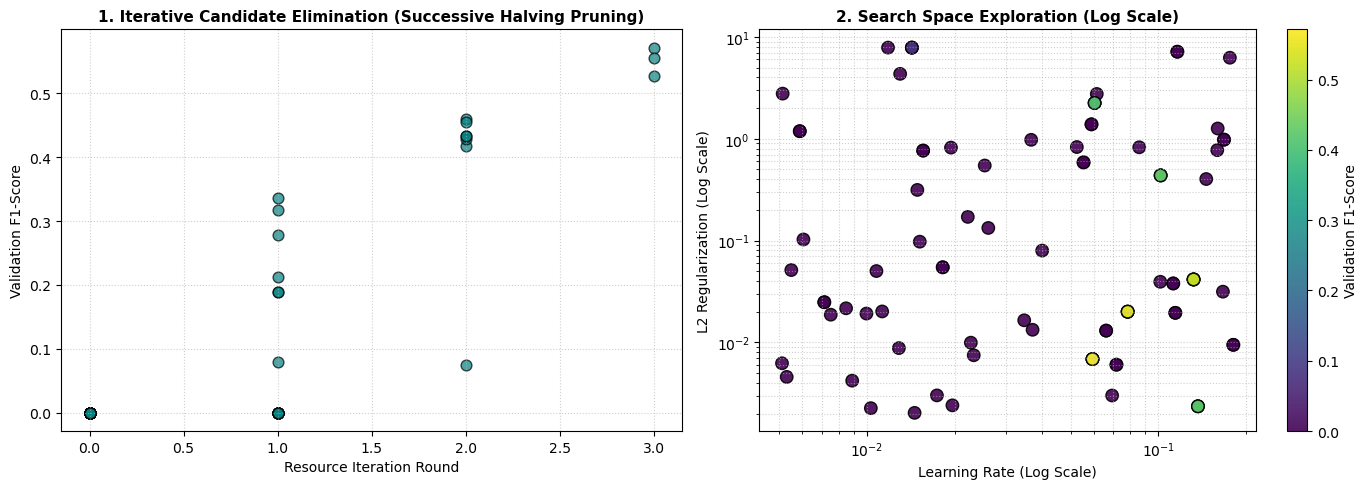

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

iterations = cv_results['iter']
scores = cv_results['mean_test_score']

axes[0].scatter(iterations, scores, color='teal', alpha=0.7, edgecolors='k', s=60)
axes[0].set_title("1. Iterative Candidate Elimination (Successive Halving Pruning)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Resource Iteration Round")
axes[0].set_ylabel("Validation F1-Score")
axes[0].grid(True, linestyle=':', alpha=0.6)

lrs = cv_results['param_classifier__learning_rate'].astype(float)
l2s = cv_results['param_classifier__l2_regularization'].astype(float)

scatter = axes[1].scatter(lrs, l2s, c=scores, cmap='viridis', s=80, edgecolors='black', alpha=0.9)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title("2. Search Space Exploration (Log Scale)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Learning Rate (Log Scale)")
axes[1].set_ylabel("L2 Regularization (Log Scale)")
axes[1].grid(True, linestyle=':', alpha=0.6, which='both')

cbar = fig.colorbar(scatter, ax=axes[1])
cbar.set_label("Validation F1-Score")

plt.tight_layout()
plt.show()